# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name: Koen van der Heide**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:  1,380649×10−23 J/K**  




In [2]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [5]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
#Ruwe data + onzekerheden
def vijfhalf(x):
    return 0.03*10**-2 *x +0.004*10**-2*4
def driehalf(x):
    return 1.5*10**-2 * x+0.01*10**-2*40

#Constante
R2= 1000
Onzekerheid_R=vijfhalf(R2)
q=-1.6022e-19
n=2
Onzekerheid_n=0.1
T = 293.15
Onzekerheid_T=1
R1=33*10**3
R3=0.1*10**3



U_R=np.array([0.011,0.034,0.099,0.204,0.367,0.606,0.765,0.956,1.180,1.453,1.773,2.594,4.457,5.299,6.240,8.630,11.684,20.939,29.430,32.875,58.750,79.943,116.073,149.275,184.470])*10**-3                             #U_R = met 51/2
Onzekerheid_UR=vijfhalf(U_R)
U_bron=np.array([0.09,0.19,0.39,0.59,0.79,0.99,1.09,1.19,1.29,1.4,1.49,1.69,1.99,2.09,2.19,2.39,2.59,2.98,3.285,3.39,3.98,4.38,4.98,5.48,5.98])*(R3/(R3+R2))                               #3 1/2
Onzekerheid_Ubron=driehalf(U_bron)




U_D=U_bron-U_R
Onzekerheid_UD = np.sqrt(Onzekerheid_Ubron**2+Onzekerheid_UR**2)
#De voltage over de weerstand






# Processing
**Description of processing of raw data into scientific evidence:**


In [7]:
#Bewerkte data
# Verhouding zou moeten zijn:I_D= I_nul*(np.e**((-q*U_D)/(n*k_B*T))-1) of in een loglog plot log(I_D)=log(I_nul)*log(e^gedoetje). Hierbij is log(I_nul) b en log(e^gedoetje) a met y=ax+b
I_D=U_R/R2
Onzekerheid_ID = I_D*np.sqrt(((Onzekerheid_UR/U_R)**2)+((Onzekerheid_R/R2)**2))




#daarna kan je er een logfunctie van maken

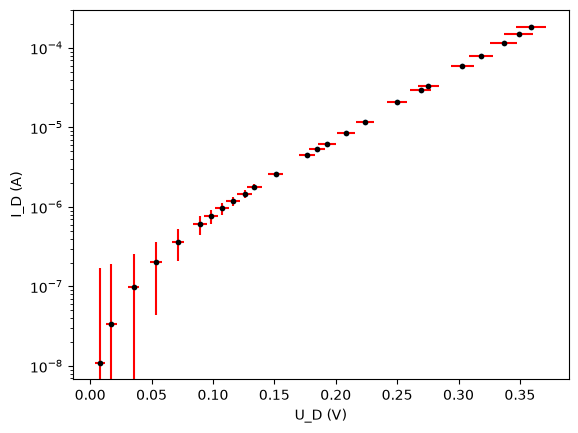

In [8]:
#Plot
#loglog plot maken
xerr= Onzekerheid_UD
yerr= Onzekerheid_ID
plt.figure
plt.plot(U_D,I_D,'.')
plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'r',label = 'punten met error')
plt.xlabel('U_D (V)')
plt.ylabel('I_D (A)')
plt.yscale('log')           #Het lineaniseren van de grafiek

-16.012869452944496
B =20.713444 met een onzekerheid van 0.100316
Constante van boltzmann is 0.000000000000000000000013193029 +/- 0.000000000000000000000000664265 J/K
1.3857294202220954e-23


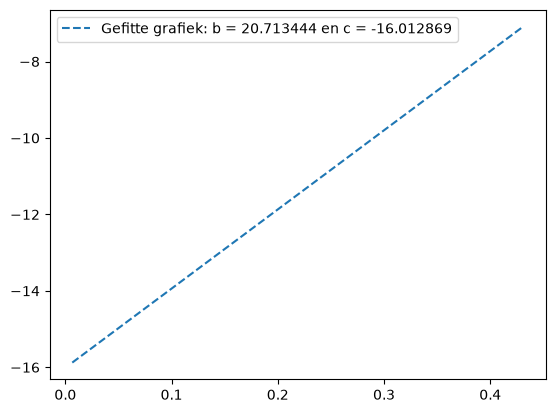

In [18]:
#Fit met y=bx+c
def functie(x,b,c):
    return b*x+c
values,covariances=curve_fit(functie, U_D[U_D>0.1],np.log(I_D[U_D>0.1])) # nplog omdat y alleen 'gelogt' wordt. 
helling_b=values[0]
afsnede_c=values[1]
Onzekerheid_b=np.sqrt(covariances[0,0])

#testlijn maken
x_test = np.linspace(0.8*min(U_D),1.2*max(U_D),1000)
y_test = functie(x_test,values[0],values[1])
plt.plot(x_test,y_test,'--', label='Gefitte grafiek: b = %f en c = %f' %(values[0],values[1]))
plt.legend()
print(afsnede_c)

#Boltzmann berekenen

k_B =-q/(helling_b*n*T)
Onzekerheid_k_B=k_B*np.sqrt((Onzekerheid_b/helling_b)**2+(Onzekerheid_n/n)**2+(Onzekerheid_T/T)**2)

print('B =%f met een onzekerheid van %f'%(helling_b,Onzekerheid_b))
print('Constante van boltzmann is %.30f +/- %.30f J/K'%(k_B,Onzekerheid_k_B))
print(k_B+Onzekerheid_k_B)

**Describing the pattern in the processed data:**  


B =20.383621 met een onzekerheid van 0.050720
Constante van boltzmann is 1.34065 *10**-23 +/- 0.06727*10**-23 J/K


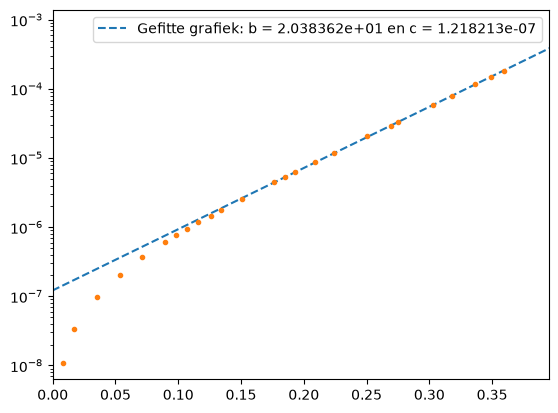

In [52]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
#Fit met y=bx+c
def functie(x,b,c):
    return c*np.e**(b*x)


values,covariances=curve_fit(functie, U_D[U_D>0.1],I_D[U_D>0.1]) #U_D moet groter zijn dan 0.1 omdat vanaf 0.1 Volt er een lineaire lijn te bepalen is volgens een fitfunctie 
helling_b=values[0]
afsnede_c=values[1]
Onzekerheid_b=np.sqrt(covariances[0,0])

#testlijn maken
x_test = np.linspace(-1*min(U_D),1.2*max(U_D),1000)
y_test = functie(x_test,values[0],values[1])
plt.plot(x_test,y_test,'--', label='Gefitte grafiek: b = %e en c = %e' %(values[0],values[1]))
plt.xlim(0,1.1*max(U_D))
plt.yscale('log')
plt.legend()
plt.plot(U_D,I_D,'.')

#Boltzmann berekenen

k_B =-q/(helling_b*n*T)
Onzekerheid_k_B=k_B*np.sqrt((Onzekerheid_b/helling_b)**2+(Onzekerheid_n/n)**2+(Onzekerheid_T/T)**2)

print('B =%f met een onzekerheid van %f'%(helling_b,Onzekerheid_b))
print('Constante van boltzmann is %.5f *10**-23 +/- %.5f*10**-23 J/K'%(k_B*10**23,Onzekerheid_k_B*10**23))

**Notes:HET IS GELUKTTTTT!!!! JIPPIE**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc